<a href="https://colab.research.google.com/github/dinahabibb/assignment1_LearningFromData/blob/main/assignment1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [33]:
import numpy as np
import pandas as pd

In [34]:
# from google.colab import drive
# drive.mount('/content/drive')
# df = pd.read_csv('/content/drive/MyDrive/vehicle_fuel.csv')
df = pd.read_csv('vehicle_fuel.csv')

**Question 1 (a)**

In [35]:
#Check if all attributes except car_name have a numeric data type
print(df.columns)
print(df.info())

Index(['fuel_eff', 'cylinders', 'engine_size', 'horsepower', 'weight',
       'acceleration', 'model_year', 'origin', 'car_name'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fuel_eff      320 non-null    float64
 1   cylinders     320 non-null    int64  
 2   engine_size   320 non-null    int64  
 3   horsepower    320 non-null    str    
 4   weight        320 non-null    int64  
 5   acceleration  320 non-null    float64
 6   model_year    320 non-null    int64  
 7   origin        320 non-null    int64  
 8   car_name      320 non-null    str    
dtypes: float64(2), int64(5), str(2)
memory usage: 22.6 KB
None


In [36]:
compact_summary = []
numeric_attribute = df.select_dtypes(include=[np.number]).columns

for row in numeric_attribute:
  meanVal = df[row].mean()
  medianVal = df[row].median()

  if meanVal != 0: #We are going to divide by the mean value so we have to check if it is not zero, to avoid division by zero.
    rel_diff = abs(meanVal - medianVal) / meanVal * 100
  else:
    rel_diff = 0.0

  if rel_diff > 10:
    verdict = "High"
  else:
    verdict = "Low"

  compact_summary.append({
      'Attribute': row,
      'Mean': round(meanVal, 2),
      'Median': round(medianVal, 2),
      'Deviation %': f"{round(rel_diff, 2)}%",
      'Verdict': verdict
  })

compact_summaryy = pd.DataFrame(compact_summary)

display(compact_summaryy.style.hide(axis='index'))

Attribute,Mean,Median,Deviation %,Verdict
fuel_eff,13.390000,14.000000,4.53%,Low
cylinders,5.340000,4.000000,25.15%,High
engine_size,2985.530000,2320.000000,22.29%,High
weight,1333.100000,1238.000000,7.13%,Low
acceleration,17.520000,17.600000,0.47%,Low
model_year,2016.070000,2016.000000,0.0%,Low
origin,1.630000,1.000000,38.58%,High


**Question 1 (b)**

The attributes that need further investigation are:
- cylinders
- engine_size
- origin
Because their deviation % is high.

When the mean is clearly larger than the median it means that the data is right-skewed.

**Question 1 (c)**

In [37]:
original_df = pd.read_csv('vehicle_fuel.csv')
numeric_cols = [col for col in original_df.columns if col != 'car_name']

for col in numeric_cols:
    #Convert to numeric (missing values become NaN)
    converted = pd.to_numeric(original_df[col], errors='coerce')

    missing_rows = original_df[converted.isna()]

    #check if there are missing/bad values
    if len(missing_rows) > 0:
        print(
            f"Attribute '{col}' has {len(missing_rows)} non-numeric/missing record(s):"
        )
        # Show car name alongside the bad value from original df
        print(missing_rows[['car_name', col]])

Attribute 'horsepower' has 7 non-numeric/missing record(s):
            car_name horsepower
8           bmw 520i          ?
63   chevrolet cruze          ?
129    ford explorer          ?
188        volvo s60          ?
241       honda jazz          ?
297    buick enclave          ?
313   toyota corolla          ?


In [51]:
#Turn missing text into NaN
df['horsepower'] = pd.to_numeric(df['horsepower'], errors='coerce')

# Replace NaN values with the median
horsepower_median = df['horsepower'].median()
df['horsepower'] = df['horsepower'].fillna(horsepower_median)

#horsepower is all numeric, and mean/median can be calculated
print("Horsepower Mean:", df['horsepower'].mean())
print("Horsepower Median:", df['horsepower'].median())

Horsepower Mean: 149.434375
Horsepower Median: 121.0


**Question 1 (d)**

In [39]:
# Check how many unique values each flagged attribute has
flagged_cols = ['cylinders', 'engine_size', 'horsepower', 'origin']

for col in flagged_cols:
    unique_count = df[col].nunique()
    print(f"Attribute '{col}': {unique_count} distinct values")

Attribute 'cylinders': 5 distinct values
Attribute 'engine_size': 211 distinct values
Attribute 'horsepower': 156 distinct values
Attribute 'origin': 3 distinct values


The two attributes with only a handful of choices are "cylinders" and "origin"

Cause: The high deviation between the mean and median is caused by how the values are distributed

For cylinders, most cars have 4 cylinders (setting the median to 4), but a smaller group of real 8-cylinder cars pulls the average up to 5.45

For origin, North American cars (code 1) make up more than half the dataset (setting the median to 1), while European (code 2) and Asian (code 3) cars pull the average up to 1.57

**Question 2 Part A**

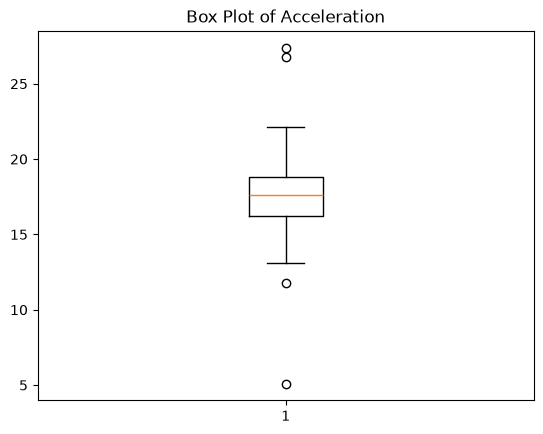

In [50]:
import matplotlib.pyplot as plt

plt.boxplot(original_df['acceleration'].dropna())
plt.title('Box Plot of Acceleration')
plt.show()


it show outliers

In [41]:
import pandas as pd

#Quartiles and IQR for acceleration
q1_acc = df['acceleration'].quantile(0.25)
q3_acc = df['acceleration'].quantile(0.75)
iqr_acc = q3_acc - q1_acc

#whisker boundaries
lower_whisker = q1_acc - 1.5 * iqr_acc
upper_whisker = q3_acc + 1.5 * iqr_acc

# Find outliers
upper_outliers = df[df['acceleration'] > upper_whisker]
lower_outliers = df[df['acceleration'] < lower_whisker]

print(f"Lower Whisker Cutoff: {lower_whisker:.2f} seconds")
print(f"Upper Whisker Cutoff: {upper_whisker:.2f} seconds")
print(f"Outliers BELOW lower whisker: {len(lower_outliers)}")
print(f"Outliers ABOVE upper whisker: {len(upper_outliers)}")

Lower Whisker Cutoff: 12.26 seconds
Upper Whisker Cutoff: 22.76 seconds
Outliers BELOW lower whisker: 2
Outliers ABOVE upper whisker: 2


In [42]:
# Show vehicle details for outliers
print("Below Lower Whisker")
display(
    lower_outliers[['car_name', 'acceleration', 'horsepower', 'engine_size']]
)

print("\nAbove Upper Whisker")
display(
    upper_outliers[['car_name', 'acceleration', 'horsepower', 'engine_size']]
)

Below Lower Whisker


,car_name,acceleration,horsepower,engine_size
14,dodge charger,11.8,278.0,6210
110,chevrolet corvette,5.1,450.0,6200



Above Upper Whisker


,car_name,acceleration,horsepower,engine_size
45,nissan micra diesel,27.4,65.0,1460
203,volkswagen polo tdi,26.8,75.0,1420


(c) Mean-Median Deviation vs. Outliers: acceleration has symmetrical outliers on both the high and low ends. The high outliers pull the mean up while the low outliers pull it down by a similar amount, causing the net mean to remain almost identical to the median. This demonstrates that comparing mean and median alone cannot detect outliers, highlighting the necessity of box plots

**Question 2 Part B**

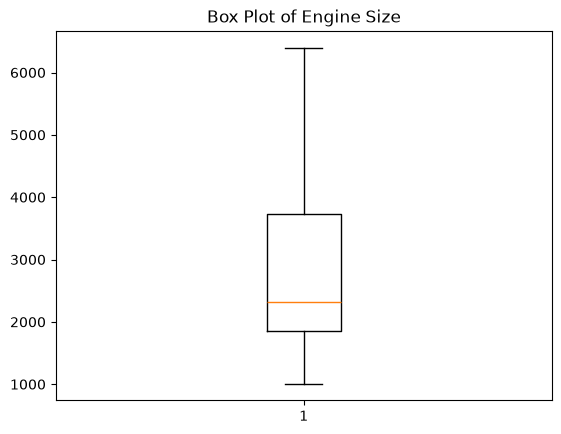

In [43]:
plt.boxplot(original_df['engine_size'].dropna())
plt.title('Box Plot of Engine Size')
plt.show()

**Question 2 Part B (a)**

In [44]:
##Calculate the actual values so we can determine the length of the lower whisker and upper whisker.
Q1 = original_df['engine_size'].quantile(0.25)
Q3 = original_df['engine_size'].quantile(0.75)
IQR = Q3 - Q1

values = original_df['engine_size'].dropna()

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

lower_endpoint = values[values >= lower_bound].min()
upper_endpoint = values[values <= upper_bound].max()

print ("Q1:", Q1)
print("Lower Endpoint:", lower_endpoint)
print("Upper Endpoint:", upper_endpoint)
print ("Q3:", Q3)

Q1: 1857.5
Lower Endpoint: 1010
Upper Endpoint: 6400
Q3: 3730.0


- There are no outliers noticed.
- The median is not in the middle, which means that it is right-skewed.
- The length of the lower whisker is approximately 1860 - 1010 = 850.
- The length of the upper whisker is approximately 6400 - 3700 = 2700.
- This means that the upper whisker is significantly longer than the lower whisker.

**Question 2 Part B (b)**

In [45]:
# Express the length of each whisker as a percentage of it's maximum permissible.
lower_percentage = (Q1 - lower_endpoint) / (1.5 * IQR) * 100
upper_percentage = (upper_endpoint - Q3) / (1.5 * IQR) * 100

print("Lower Whisker Percentage:", round(lower_percentage, 2), "%")
print("Upper Whisker Percentage:", round(upper_percentage, 2), "%")


Lower Whisker Percentage: 30.17 %
Upper Whisker Percentage: 95.06 %


**Question 2 Part B (c)**

- No, it is not caused by ouliers as there is no outliers present.
- The high deviation flagged in Question 1 is caused by the distribution of the data where the majority of the engine sizes are concentrated on the lower end as the median is below the 50%, while a smaller group of larger engines streches the upper tail outward.

**Question 2 Part C**

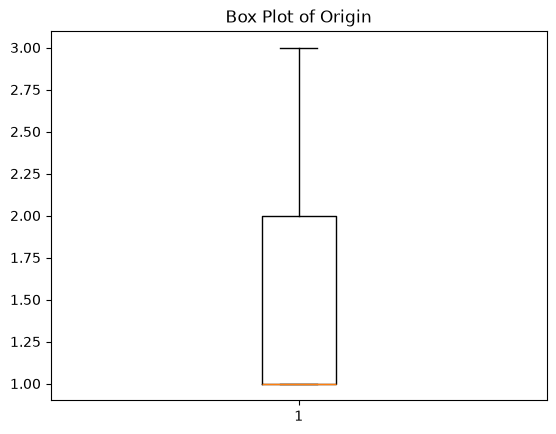

In [46]:
plt.boxplot(original_df['origin'].dropna())
plt.title('Box Plot of Origin')
plt.show()

**Question 2 Part C (a)**

- Q1 = Median = Lower value in data
- That's why there is no lower whisker

**Question 2 Part C (b)**

In [47]:
freq = original_df['origin'].value_counts().sort_index()
cumulative_freq = freq.cumsum()

frequency_table = pd.DataFrame({
    'Frequency': freq,
    'Cumulative Frequency': cumulative_freq
})

display(frequency_table)

,Frequency,Cumulative Frequency
origin,,
1,190,190
2,59,249
3,71,320


- Q1 falls at "1".
- Q2 falls at "1"
- Q3 falls at "2"

- There is nothing wrong with the data, but since
 Q1 = Q2 the box plot can look unusual while the data itself is fine.

In [48]:
import seaborn as sns

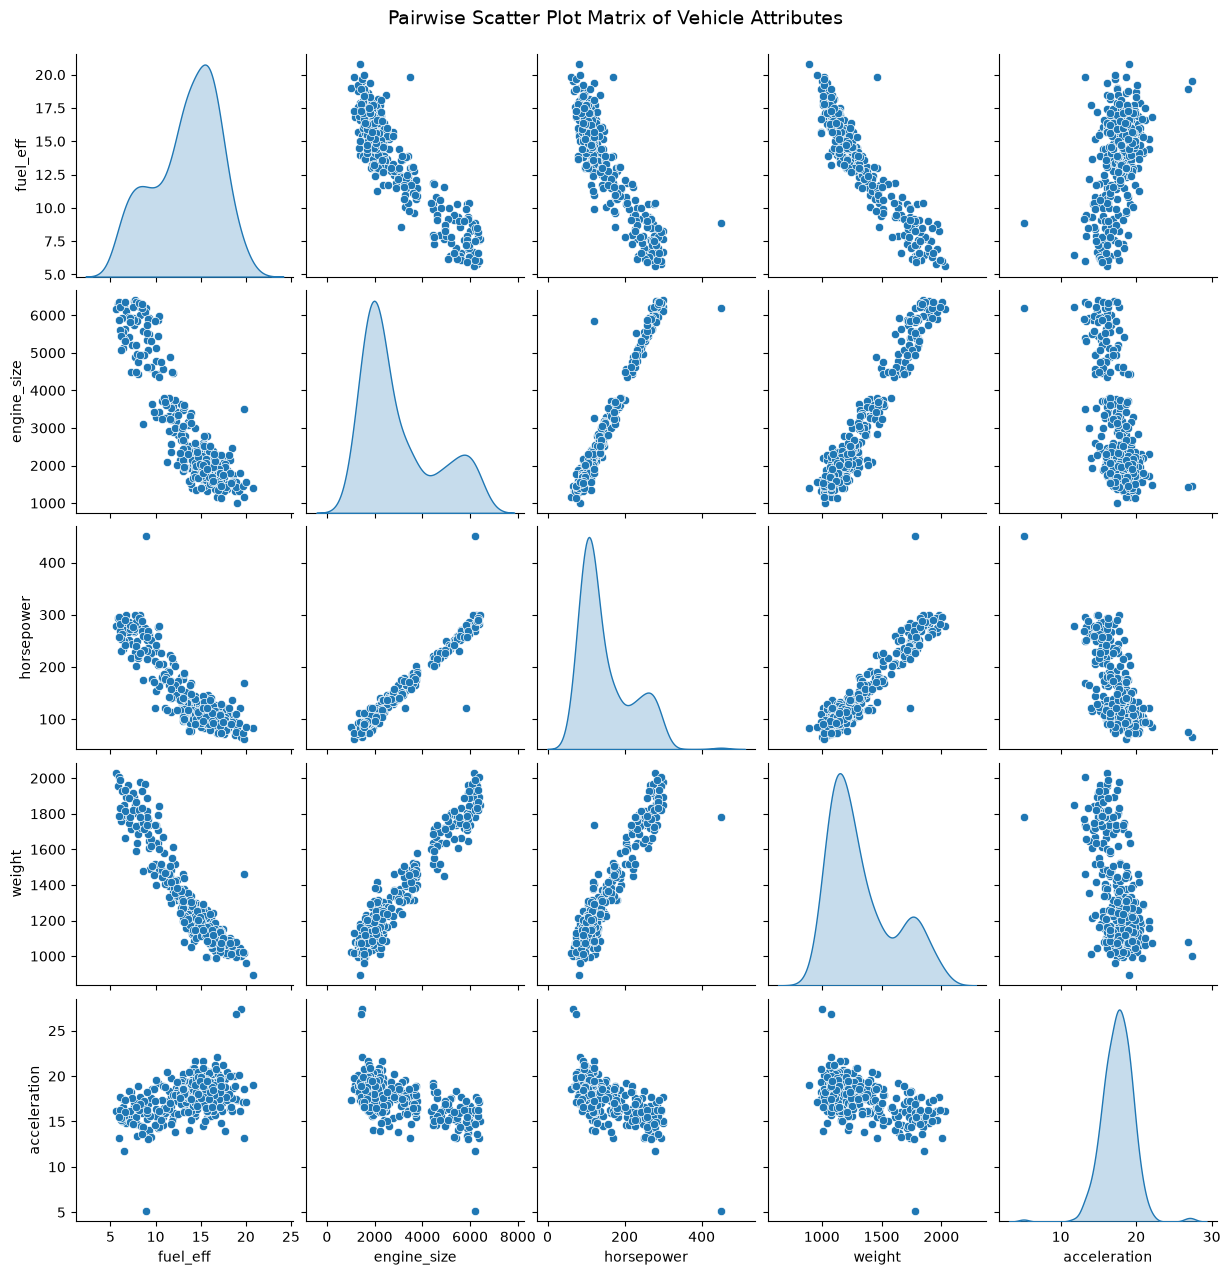

In [53]:
import matplotlib.pyplot as plt

# Selected attributes for Question 3
q3_cols = ['fuel_eff', 'engine_size', 'horsepower', 'weight', 'acceleration']

# Draw the 5x5 pairwise scatter matrix
sns.pairplot(df[q3_cols], corner=False, diag_kind='kde')

plt.suptitle(
    'Pairwise Scatter Plot Matrix of Vehicle Attributes', y=1.02, fontsize=14
)
plt.show()



Q3/A

- Attributes that show strong positive relationship are:
    - engine_size, horsepower
    - engine_size, weight
    - horsepower, weight

- Attributes that show tightest band of points are:
    - engine_size, horsepower
    - engine_size, weight
    -horse_power, weight

Q3/B


- fuel_eff has negative relation with engine_size, horsepower and weight.
- not perfectly linear
- fuel_eff has the strongest relation with weight